# Imports

In [5]:

!pip install -q sacrebleu

In [6]:
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader
import transformers
from datasets import Dataset, DatasetDict, load_dataset
from sklearn.model_selection import train_test_split
from sacrebleu.metrics import BLEU, CHRF
from tqdm.auto import tqdm
from IPython.display import display

In [ ]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_float32_matmul_precision('high')
print(device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name())

ARTIFACTS = Path('01B_seq2seq_artifacts')
ARTIFACTS.mkdir(exist_ok=True)

# Dataset

Get the dataset from [here](https://tatoeba.org/en/downloads). Preferably use russian to english translations.

Use a custom tokenizer that can add bos and eos tokens (pass `add_special_tokens=True` when calling the tokenizer to add them).

In [8]:
class Tokenizer(transformers.GPT2Tokenizer):
    def build_inputs_with_special_tokens(self, token_ids_0, token_ids_1=None):
        if token_ids_1 is None:
            return [self.bos_token_id, *token_ids_0, self.eos_token_id]
        return [self.bos_token_id, *token_ids_0, self.bos_token_id,
                *token_ids_1, self.eos_token_id]

    def __call__(self, text, add_special_tokens=True):
        encoded = super().__call__(text, add_special_tokens=False)
        if add_special_tokens:
            batch = isinstance(text, (list, tuple))
            ids = encoded['input_ids'] if batch else [encoded['input_ids']]
            ids = [self.build_inputs_with_special_tokens(row) for row in ids]
            masks = [[1] * len(row) for row in ids]
            encoded['input_ids'] = ids if batch else ids[0]
            encoded['attention_mask'] = masks if batch else masks[0]
        return encoded

In [9]:
tokenizer = Tokenizer.from_pretrained('gpt2')
tokenizer.add_special_tokens({'bos_token': '<|bos|>', 'pad_token': '<|pad|>'})
PAD = tokenizer.pad_token_id
BOS = tokenizer.bos_token_id
EOS = tokenizer.eos_token_id
print('Размер словаря:', len(tokenizer))
print('BOS, EOS, PAD:', BOS, EOS, PAD)
print('Пример:', tokenizer('Hello!', add_special_tokens=True)['input_ids'])
tokenizer.save_pretrained(ARTIFACTS / 'tokenizer');

Размер словаря: 50259
BOS, EOS, PAD: 50257 50256 50258
Пример: [50257, 15496, 0, 50256]


Since the dataset is rather large, you can omit the validation dataset and just use a set of test sentences after the training.

Create a dataset that returns the following
* A pair of tensors `((None, L), (None, P))` -- input sequence of tokens and output sequence of tokens to be fed into decoder (this should start with the BOS token)
* A tensor `(None, P)` -- output sequence of tokens to be predicted (this should end with EOS token)
* A tensor `(None, P)` -- a masking tensor marking padded tokens with 0

In [10]:
DATASET_NAME = 'sentence-transformers/parallel-sentences-tatoeba'
DATASET_REVISION = 'cec1343ab5a7a8befe99af4a2d0ca847b6c84743'
MAX_SOURCE_LEN = 96
MAX_TARGET_LEN = 48

raw = load_dataset(DATASET_NAME, 'en-ru', revision=DATASET_REVISION)
print('Tatoeba:', 'https://tatoeba.org/en/downloads')
print('Зеркало:', f'https://huggingface.co/datasets/{DATASET_NAME}')
print(raw)

frames = {}
for split in ['train', 'dev']:
    frame = raw[split].to_pandas().rename(columns={'non_english': 'ru', 'english': 'en'})
    frame = frame.dropna(subset=['ru', 'en'])
    for column in ['ru', 'en']:
        frame[column] = frame[column].str.replace(r'\s+', ' ', regex=True).str.strip()
    frame = frame[(frame.ru != '') & (frame.en != '')].drop_duplicates(['ru', 'en'])
    frame['key'] = frame.ru.str.casefold()
    frames[split] = frame.reset_index(drop=True)

test_frame = frames['dev']
pool = frames['train'][~frames['train'].key.isin(test_frame.key)]
train_keys, val_keys = train_test_split(pool.key.unique(), test_size=0.05, random_state=SEED)
frames = {
    'train': pool[pool.key.isin(train_keys)],
    'validation': pool[pool.key.isin(val_keys)],
    'test': test_frame,
}
data = DatasetDict({name: Dataset.from_pandas(frame, preserve_index=False)
                    for name, frame in frames.items()})

def encode_pairs(batch):
    return {
        'source_ids': tokenizer(batch['ru'], add_special_tokens=True)['input_ids'],
        'target_ids': tokenizer(batch['en'], add_special_tokens=True)['input_ids'],
    }

data = data.map(encode_pairs, batched=True, desc='Токенизация')
before_filter = {name: len(part) for name, part in data.items()}
data = data.filter(lambda row: len(row['source_ids']) <= MAX_SOURCE_LEN
                   and len(row['target_ids']) <= MAX_TARGET_LEN)
display(pd.DataFrame({
    'До ограничения длины': before_filter,
    'После ограничения длины': {name: len(part) for name, part in data.items()},
}))
print('Длинные пары исключены целиком. Длины включают BOS и EOS.')
print('Тестовые метрики относятся к предложениям в этих пределах длины.')
display(data['train'].select(np.random.default_rng(SEED).choice(len(data['train']), 5, replace=False)).to_pandas()[['ru', 'en']])

pd.DataFrame([{
    'dataset': DATASET_NAME, 'revision': DATASET_REVISION,
    'seed': SEED, 'max_source_len': MAX_SOURCE_LEN, 'max_target_len': MAX_TARGET_LEN,
}]).to_json(ARTIFACTS / 'data_settings.json', orient='records', indent=2)

Generating train split: 100%|██████████| 541666/541666 [00:01<00:00, 347764.09 examples/s]


Tatoeba: https://tatoeba.org/en/downloads
Зеркало: https://huggingface.co/datasets/sentence-transformers/parallel-sentences-tatoeba
DatasetDict({
    dev: Dataset({
        features: ['english', 'non_english'],
        num_rows: 1618
    })
    train: Dataset({
        features: ['english', 'non_english'],
        num_rows: 541666
    })
})


Filter: 100%|██████████| 1618/1618 [00:00<00:00, 190923.73 examples/s]


,До ограничения длины,После ограничения длины
train,514104,510038
validation,27022,26820
test,1618,1551


Длинные пары исключены целиком. Длины включают BOS и EOS.
Тестовые метрики относятся к предложениям в этих пределах длины.


,ru,en
0,Мне следовало это предвидеть.,I ought to have anticipated this.
1,Ты ещё занят?,Are you still busy?
2,Я сделал это всё самостоятельно.,I did that all by myself.
3,Молодые люди любят его книги.,Young people like his books.
4,"У вас есть то, чего они хотят.",You have what they want.


In [11]:
BATCH_SIZE = 64

def collate_batch(rows):
    source = [torch.tensor(row['source_ids']) for row in rows]
    targets = [torch.tensor(row['target_ids']) for row in rows]
    source = pad_sequence(source, batch_first=True, padding_value=PAD)
    decoder_input = pad_sequence([row[:-1] for row in targets], batch_first=True, padding_value=PAD)
    labels = pad_sequence([row[1:] for row in targets], batch_first=True, padding_value=PAD)
    return (source, decoder_input), labels, labels.ne(PAD)

val_loader = DataLoader(data['validation'], batch_size=BATCH_SIZE, collate_fn=collate_batch)
test_loader = DataLoader(data['test'], batch_size=BATCH_SIZE, collate_fn=collate_batch)
inputs, labels, mask = collate_batch([data['train'][i] for i in range(3)])
print('Encoder:', inputs[0].shape, 'Decoder:', inputs[1].shape)
print('Labels:', labels.shape, 'Mask:', mask.shape)
print('Decoder input:', tokenizer.decode(inputs[1][0].tolist()))
print('Expected output:', tokenizer.decode(labels[0].tolist()))

Encoder: torch.Size([3, 50]) Decoder: torch.Size([3, 9])
Labels: torch.Size([3, 9]) Mask: torch.Size([3, 9])
Decoder input: <|bos|>You should have accepted his advice.<|pad|>
Expected output: You should have accepted his advice.<|endoftext|><|pad|>


# Model

Create a model for training. The model should have two inputs: input sequence `(None, L)` and output sequence`(None, P)`. The model output is a single tensor `(None, P)` logits (or probabilities) of the next token predicted for each input one.

In [12]:
class GRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_linear = nn.Linear(input_size, 3 * hidden_size)
        self.hidden_linear = nn.Linear(hidden_size, 3 * hidden_size)

    def forward(self, x, h):
        x_r, x_z, x_n = self.input_linear(x).chunk(3, dim=-1)
        h_r, h_z, h_n = self.hidden_linear(h).chunk(3, dim=-1)
        r = torch.sigmoid(x_r + h_r)
        z = torch.sigmoid(x_z + h_z)
        n = torch.tanh(x_n + r * h_n)
        return (1 - z) * n + z * h


class Seq2Seq(nn.Module):
    def __init__(self, units, n_tokens, n_labels, embedding_dim=128):
        super().__init__()
        self.units = units
        self.source_embedding = nn.Embedding(n_tokens, embedding_dim, padding_idx=PAD)
        self.target_embedding = nn.Embedding(n_labels, embedding_dim, padding_idx=PAD)
        self.encoder_cell = GRUCell(embedding_dim, units)
        self.decoder_cell = GRUCell(embedding_dim + units, units)
        self.output = nn.Linear(2 * units, n_labels)
        self.dropout = nn.Dropout(0.2)

    def encode(self, source):
        embedded = self.dropout(self.source_embedding(source))
        mask = source.ne(PAD)
        h = embedded.new_zeros(source.size(0), self.units)
        states = []
        for step in range(source.size(1)):
            new_h = self.encoder_cell(embedded[:, step], h)
            h = torch.where(mask[:, step, None], new_h, h)
            states.append(h)
        return torch.stack(states, dim=1), h, mask

    def prepare_memory(self, states, final_state, mask):
        return final_state

    def get_context(self, h, memory):
        return memory

    def decode_step(self, token, h, memory):
        context = self.get_context(h, memory)
        embedded = self.dropout(self.target_embedding(token))
        h = self.decoder_cell(torch.cat([embedded, context], dim=-1), h)
        features = self.dropout(torch.cat([h, context], dim=-1))
        return features, h

    def forward(self, source, decoder_input):
        states, h, mask = self.encode(source)
        memory = self.prepare_memory(states, h, mask)
        outputs = []
        for step in range(decoder_input.size(1)):
            features, h = self.decode_step(decoder_input[:, step], h, memory)
            outputs.append(features)
        return self.output(torch.stack(outputs, dim=1))


def get_model(units, n_tokens, n_labels, attention=False):
    model_class = AttentionSeq2Seq if attention else Seq2Seq
    return model_class(units, n_tokens, n_labels)

Try to add attention to your model (for example [additive attention](https://keras.io/api/layers/attention_layers/additive_attention/)), does it perform better?

In [13]:
class AttentionSeq2Seq(Seq2Seq):
    def __init__(self, units, n_tokens, n_labels, embedding_dim=128):
        super().__init__(units, n_tokens, n_labels, embedding_dim)
        self.key = nn.Linear(units, units, bias=False)
        self.query = nn.Linear(units, units, bias=False)
        self.energy = nn.Linear(units, 1, bias=False)

    def prepare_memory(self, states, final_state, mask):
        return states, self.key(states), mask

    def get_context(self, h, memory):
        states, keys, mask = memory
        scores = self.energy(torch.tanh(keys + self.query(h).unsqueeze(1))).squeeze(-1)
        weights = scores.masked_fill(~mask, float('-inf')).softmax(dim=-1)
        return torch.bmm(weights.unsqueeze(1).to(states.dtype), states).squeeze(1)

# Training

Train your model using teacher forcing. The idea is that the model predicts the next token that should follow, so one part of the model (called encoder) reads the text and output some state containing information about the text read. The other part of the model (called decoder) reads an already generated text (or in case of the teacher forcing the expected output) and predicts the next token for each one. 

In [14]:
UNITS = 256
EPOCHS = 15
PATIENCE = 3
LEARNING_RATE = 0.001


def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss = 0.0
    total_tokens = 0
    correct = 0
    with torch.set_grad_enabled(training):
        for (source, decoder_input), labels, mask in tqdm(loader, leave=False):
            source, decoder_input = source.to(device), decoder_input.to(device)
            labels, mask = labels.to(device), mask.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.bfloat16,
                                enabled=device.type == 'cuda'):
                logits = model(source, decoder_input)
                losses = F.cross_entropy(logits.flatten(0, 1), labels.flatten(),
                                         ignore_index=PAD, reduction='none').view_as(labels)
                loss = (losses * mask).sum() / mask.sum()
            if training:
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            count = mask.sum().item()
            total_tokens += count
            total_loss += loss.item() * count
            correct += ((logits.argmax(-1) == labels) & mask).sum().item()
    return total_loss / total_tokens, correct / total_tokens


def train_model(name, attention):
    set_seed()
    model = get_model(UNITS, len(tokenizer), len(tokenizer), attention).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=1, factor=0.5)
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(data['train'], batch_size=BATCH_SIZE, shuffle=True,
                        generator=generator, collate_fn=collate_batch)
    history = []
    best_loss = float('inf')
    stale_epochs = 0
    started = time.perf_counter()
    path = ARTIFACTS / f'{name}.pt'
    for epoch in range(1, EPOCHS + 1):
        train_loss, train_accuracy = run_epoch(model, loader, optimizer)
        val_loss, val_accuracy = run_epoch(model, val_loader)
        history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
                        'train_accuracy': train_accuracy, 'val_accuracy': val_accuracy,
                        'learning_rate': optimizer.param_groups[0]['lr']})
        print(f'{name}, эпоха {epoch}: train loss={train_loss:.4f}, val loss={val_loss:.4f}')
        scheduler.step(val_loss)
        if val_loss < best_loss:
            best_loss = val_loss
            stale_epochs = 0
            torch.save({'state_dict': model.state_dict(), 'epoch': epoch,
                        'val_loss': val_loss, 'attention': attention,
                        'units': UNITS, 'vocab_size': len(tokenizer),
                        'pad_id': PAD, 'bos_id': BOS, 'eos_id': EOS}, path)
        else:
            stale_epochs += 1
        pd.DataFrame(history).to_csv(ARTIFACTS / f'{name}_history.csv', index=False)
        if stale_epochs >= PATIENCE:
            break
    return {'name': name, 'attention': attention, 'history': pd.DataFrame(history),
            'val_loss': best_loss, 'seconds': time.perf_counter() - started,
            'parameters': sum(p.numel() for p in model.parameters()), 'checkpoint': path}

GRU, эпоха 1: train loss=2.1931, val loss=1.5099


GRU, эпоха 2: train loss=1.4600, val loss=1.3082


GRU, эпоха 3: train loss=1.2817, val loss=1.2306


GRU, эпоха 4: train loss=1.1858, val loss=1.1868


GRU, эпоха 5: train loss=1.1226, val loss=1.1529


...

GRU_attention, эпоха 11: train loss=0.8108, val loss=0.9420


GRU_attention, эпоха 12: train loss=0.7995, val loss=0.9390


GRU_attention, эпоха 13: train loss=0.7895, val loss=0.9337


GRU_attention, эпоха 14: train loss=0.7803, val loss=0.9326


GRU_attention, эпоха 15: train loss=0.7732, val loss=0.9334
Выбрана по validation loss: GRU_attention


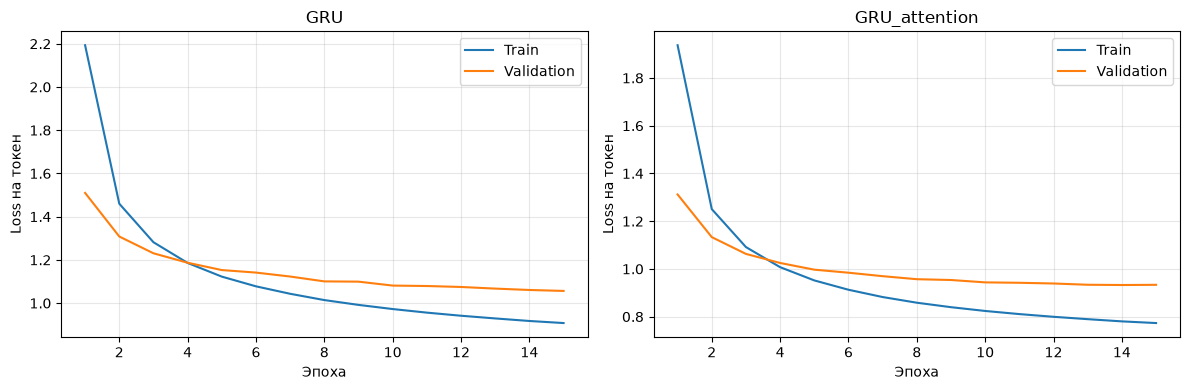

In [15]:
runs = {}
for name, attention in [('GRU', False), ('GRU_attention', True)]:
    runs[name] = train_model(name, attention)

best_name = min(runs, key=lambda name: runs[name]['val_loss'])
print('Выбрана по validation loss:', best_name)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, run) in zip(axes, runs.items()):
    history = run['history']
    ax.plot(history.epoch, history.train_loss, label='Train')
    ax.plot(history.epoch, history.val_loss, label='Validation')
    ax.set(title=name, xlabel='Эпоха', ylabel='Loss на токен')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Testing

Make a function for text translation. Translate some text and evaluate model performance.

Take note that your model is set for training. During the inference process you will have to use parts of the model independently (including the RNN cells).

In [16]:
@torch.no_grad()
def generate(model, source, max_len=MAX_TARGET_LEN - 1):
    model.eval()
    states, h, mask = model.encode(source)
    memory = model.prepare_memory(states, h, mask)
    token = torch.full((source.size(0),), BOS, dtype=torch.long, device=source.device)
    finished = torch.zeros(source.size(0), dtype=torch.bool, device=source.device)
    generated = []
    for step in range(max_len):
        features, h = model.decode_step(token, h, memory)
        logits = model.output(features)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(dim=-1)
        token = torch.where(finished, EOS, token)
        generated.append(token)
        finished = finished | token.eq(EOS)
        if finished.all():
            break
    return torch.stack(generated, dim=1)


def translate(text, tokenizer, model, max_len=MAX_TARGET_LEN - 1):
    ids = tokenizer(text, add_special_tokens=True)['input_ids']
    source = torch.tensor([ids], device=next(model.parameters()).device)
    prediction = generate(model, source, max_len=max_len)[0].tolist()
    return tokenizer.decode(prediction, skip_special_tokens=True).strip()


def load_model(run):
    checkpoint = torch.load(run['checkpoint'], map_location='cpu', weights_only=True)
    model = get_model(checkpoint['units'], checkpoint['vocab_size'],
                      checkpoint['vocab_size'], checkpoint['attention'])
    model.load_state_dict(checkpoint['state_dict'])
    return model.to(device).eval()

In [17]:
test_frame = data['test'].to_pandas()
evaluation = test_frame.groupby('key', sort=False).agg(
    ru=('ru', 'first'), references=('en', list), source_ids=('source_ids', 'first')
).reset_index(drop=True)
reference_streams = [
    [refs[i] if i < len(refs) else None for refs in evaluation.references]
    for i in range(evaluation.references.map(len).max())
]

predictions = {}
rows = []
for name, run in runs.items():
    model = load_model(run)
    test_loss, test_accuracy = run_epoch(model, test_loader)
    hypotheses = []
    for start in tqdm(range(0, len(evaluation), BATCH_SIZE), desc=name):
        batch = evaluation.iloc[start:start + BATCH_SIZE]
        source = pad_sequence([torch.tensor(ids) for ids in batch.source_ids],
                              batch_first=True, padding_value=PAD).to(device)
        generated = generate(model, source).cpu().tolist()
        hypotheses.extend(tokenizer.decode(ids, skip_special_tokens=True).strip() for ids in generated)
    bleu = BLEU(tokenize='13a')
    chrf = CHRF()
    bleu_score = bleu.corpus_score(hypotheses, reference_streams).score
    chrf_score = chrf.corpus_score(hypotheses, reference_streams).score
    exact = np.mean([text in refs for text, refs in zip(hypotheses, evaluation.references)])
    rows.append({'Модель': name, 'BLEU (0–100)': bleu_score, 'chrF (0–100)': chrf_score,
                 'Точное совпадение, %': 100 * exact, 'Test loss': test_loss,
                 'Token accuracy, % (teacher forcing)': 100 * test_accuracy,
                 'Лучший validation loss': run['val_loss'],
                 'Обучение, мин': run['seconds'] / 60, 'Параметров': run['parameters']})
    predictions[name] = hypotheses
    output = evaluation[['ru', 'references']].copy()
    output['prediction'] = hypotheses
    output.to_csv(ARTIFACTS / f'{name}_translations.csv', index=False)
    print(name, 'BLEU:', bleu.get_signature(), 'chrF:', chrf.get_signature())
    del model

results = pd.DataFrame(rows).set_index('Модель')
results.to_csv(ARTIFACTS / 'test_results.csv')
display(results.round(3))
print('BLEU и chrF: выше — лучше. Переводы сгенерированы без подсказок из эталона.')
print('Token accuracy и loss рассчитаны отдельно с teacher forcing.')
print('Модель для примеров выбрана по validation:', best_name)

GRU: 100%|██████████| 25/25 [00:00<00:00, 34.34it/s]


GRU BLEU: nrefs:var|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0 chrF: nrefs:var|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0


GRU_attention: 100%|██████████| 25/25 [00:00<00:00, 33.44it/s]


GRU_attention BLEU: nrefs:var|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0 chrF: nrefs:var|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0


,BLEU (0–100),chrF (0–100),"Точное совпадение, %",Test loss,"Token accuracy, % (teacher forcing)",Лучший validation loss,"Обучение, мин",Параметров
Модель,,,,,,,,
GRU,25.401,42.125,12.403,1.924,65.200,1.056,155.086,39438675
GRU_attention,32.874,50.625,15.130,1.686,69.186,0.933,179.078,39570003


BLEU и chrF: выше — лучше. Переводы сгенерированы без подсказок из эталона.
Token accuracy и loss рассчитаны отдельно с teacher forcing.
Модель для примеров выбрана по validation: GRU_attention


In [18]:
example_indices = np.random.default_rng(SEED).choice(len(evaluation), min(8, len(evaluation)), replace=False)
examples = evaluation.iloc[example_indices][['ru', 'references']].copy()
for name in runs:
    examples[name] = [predictions[name][i] for i in example_indices]
with pd.option_context('display.max_colwidth', None):
    display(examples.reset_index(drop=True))

best_model = load_model(runs[best_name])
for text in ['Привет! Как дела?', 'Сегодня хорошая погода.', 'Я изучаю английский язык.']:
    print(text)
    print(translate(text, tokenizer, best_model))
    print()

,ru,references,GRU,GRU_attention
0,"Мне потребовалась бы вечность, чтобы всё объяснить.",[It would take forever for me to explain everything.],I'd like to explain everything to explain.,I'd love to be sure to explain everything.
1,Он недавно опубликовал серию интересных статей.,[He has just published an interesting series of articles.],"He recently struck the lottery, which he was a famous actor.",He recently published a hard-working interest in the middle of the article.
2,Не забудьте билет.,[Don't forget the ticket.],Don't forget the ticket.,Don't forget the ticket.
3,У кролика длинные уши и короткий хвост.,[A rabbit has long ears and a short tail.],The box has a long tail and short tails.,Rabbits have long ears and short tails.
4,"Мир меняет коммуникация, а не информация.","[What changes the world is communication, not information.]",The world is not a cute man but a fool.,"The world is changing with a social, not information."
5,Умираю от голода!,[I'm starving!],I'm dying of hunger!,I'm starving.
6,"Это и есть то слово, для которого я хотел бы найти замену.",[It's a word I'd like to find a substitute for.],That's what I'd like to find the exam.,It's the way I have a word I could find a substitute.
7,У тебя ручка с собой?,[Do you have a pen on you?],Do you have a pen with you?,Do you have a pen with you?


Привет! Как дела?
Hello! How are you?

Сегодня хорошая погода.
Today is good weather.

Я изучаю английский язык.
I study English.

